# Tarea 17 · Histogramas con KDE de antigüedad y cargo mensual

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/julianschmidt1/tpi-analisis-de-datos/blob/main/notebooks/trabajo/17_histogramas_kde.ipynb)

**TPI · Introducción al Análisis de Datos · UTN FRA · División 343**
**Integrantes:** Matías, Julián y Emmanuel. **Responsable de esta tarea:** Emmanuel.

Graficamos cómo se distribuyen la antigüedad (`tenure`) y el cargo mensual (`MonthlyCharges`) de los clientes, y comparamos esas distribuciones entre quienes se quedan y quienes se van (`Churn`). Cada gráfico se acompaña de una interpretación orientada al negocio.

**Conceptos de esta tarea**

- **Histograma:** divide los valores en rangos (*bins*) y cuenta cuántos clientes caen en cada uno. Las barras altas indican rangos donde hay muchos clientes.
- **KDE (estimación de densidad por núcleo):** una curva suave que aproxima la forma del histograma. Sirve para ver dónde se concentran los datos sin depender del ancho de las barras.

## Cómo ejecutarlo

- **Local:** instalá las dependencias de `requirements.txt`, abrí el notebook desde el repositorio y ejecutá todas las celdas.
- **Colab:** abrí el botón y elegí **Entorno de ejecución → Ejecutar todo**. Los datos se leen desde `main` de GitHub. Las imágenes quedan en `reports/figures/` dentro del panel **Archivos**.

## 1. Estilo común del TPI

Celda definida en la tarea 16: importaciones, detección de la raíz del proyecto, paleta (`No` en azul, `Yes` en naranja) y las funciones `aplicar_estilo()` y `guardar_figura(fig, nombre)`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

try:
    import google.colab
except ImportError:
    EN_COLAB = False
else:
    EN_COLAB = True

if EN_COLAB:
    RAIZ = Path.cwd()
else:
    actual = Path.cwd().resolve()
    RAIZ = next(
        (ruta for ruta in (actual, *actual.parents) if (ruta / 'PLAN_TAREAS.md').is_file()),
        None,
    )
    if RAIZ is None:
        raise FileNotFoundError('Abrí Jupyter dentro del repositorio del TPI.')

TAMANO_FIGURA = (9, 5)
DPI_EXPORTACION = 300
PALETA_CATEGORICA = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
COLORES_CHURN = {'No': '#0072B2', 'Yes': '#D55E00'}
MAPA_CORRELACION = 'vlag'
CARPETA_FIGURAS = RAIZ / 'reports' / 'figures'

def aplicar_estilo():
    """Aplica el estilo común del TPI a las figuras que se creen después."""
    sns.set_theme(
        style='whitegrid',
        context='notebook',
        font='DejaVu Sans',
        palette=PALETA_CATEGORICA,
        rc={
            'figure.figsize': TAMANO_FIGURA,
            'figure.dpi': 110,
            'figure.facecolor': 'white',
            'axes.facecolor': 'white',
            'axes.titlesize': 14,
            'axes.titleweight': 'bold',
            'axes.labelsize': 12,
            'xtick.labelsize': 11,
            'ytick.labelsize': 11,
            'legend.fontsize': 11,
            'axes.spines.top': False,
            'axes.spines.right': False,
            'grid.alpha': 0.25,
            'savefig.dpi': DPI_EXPORTACION,
            'savefig.facecolor': 'white',
        },
    )

def guardar_figura(fig, nombre):
    """Guarda fig en reports/figures/<nombre>.png a 300 dpi y devuelve Path.

    Usar un nombre sin ruta ni extensión, como '17_histograma_tenure'.
    Un nombre existente se sobrescribe para permitir regenerar el gráfico.
    Guardar antes de plt.show() y cerrar luego con plt.close(fig).
    """
    if not nombre or Path(nombre).name != nombre or Path(nombre).suffix:
        raise ValueError('Usá un nombre sin ruta ni extensión.')
    CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
    ruta = CARPETA_FIGURAS / f'{nombre}.png'
    fig.savefig(ruta, dpi=DPI_EXPORTACION, bbox_inches='tight', facecolor='white')
    return ruta

aplicar_estilo()
print('Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.')

Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.


## 2. Carga del dataset limpio

Leemos `telco_clean.csv`, generado en la tarea 9. Solo necesitamos las dos variables numéricas y `Churn`. Verificamos que no falten datos y que `Churn` tenga solo las etiquetas esperadas.

In [2]:
import numpy as np
import pandas as pd

GITHUB_REPO = 'julianschmidt1/tpi-analisis-de-datos'
GITHUB_REF = 'main'
RUTA_LIMPIA = Path('data/processed/telco_clean.csv')

if EN_COLAB:
    fuente = (
        f'https://raw.githubusercontent.com/{GITHUB_REPO}/'
        f'{GITHUB_REF}/{RUTA_LIMPIA.as_posix()}'
    )
else:
    fuente = RAIZ / RUTA_LIMPIA

df = pd.read_csv(fuente, usecols=['tenure', 'MonthlyCharges', 'Churn'])

assert not df.isna().any().any(), 'El dataset limpio no debe tener nulos.'
assert df['Churn'].isin(['No', 'Yes']).all(), 'Revisá las etiquetas de Churn.'

print(f'Fuente: {fuente}')
print(f'Clientes analizados: {len(df):,}')
display_cols = df[['tenure', 'MonthlyCharges']].describe().round(2)
display_cols

Fuente: F:\codear\analisis-datos\tpi-analisis-de-datos\data\processed\telco_clean.csv
Clientes analizados: 7,043


,tenure,MonthlyCharges
count,7043.00,7043.00
mean,32.37,64.76
std,24.56,30.09
min,0.00,18.25
25%,9.00,35.50
50%,29.00,70.35
75%,55.00,89.85
max,72.00,118.75


## 3. Antigüedad del cliente (`tenure`)

`tenure` es la cantidad de meses que el cliente lleva en la empresa. A la izquierda vemos la distribución de **todos** los clientes; a la derecha, la comparación entre quienes **se quedaron** (`No`) y quienes **se fueron** (`Yes`). Usamos la escala de densidad en el panel derecho para comparar las formas aunque haya muchos más clientes que se quedan que clientes que se van.

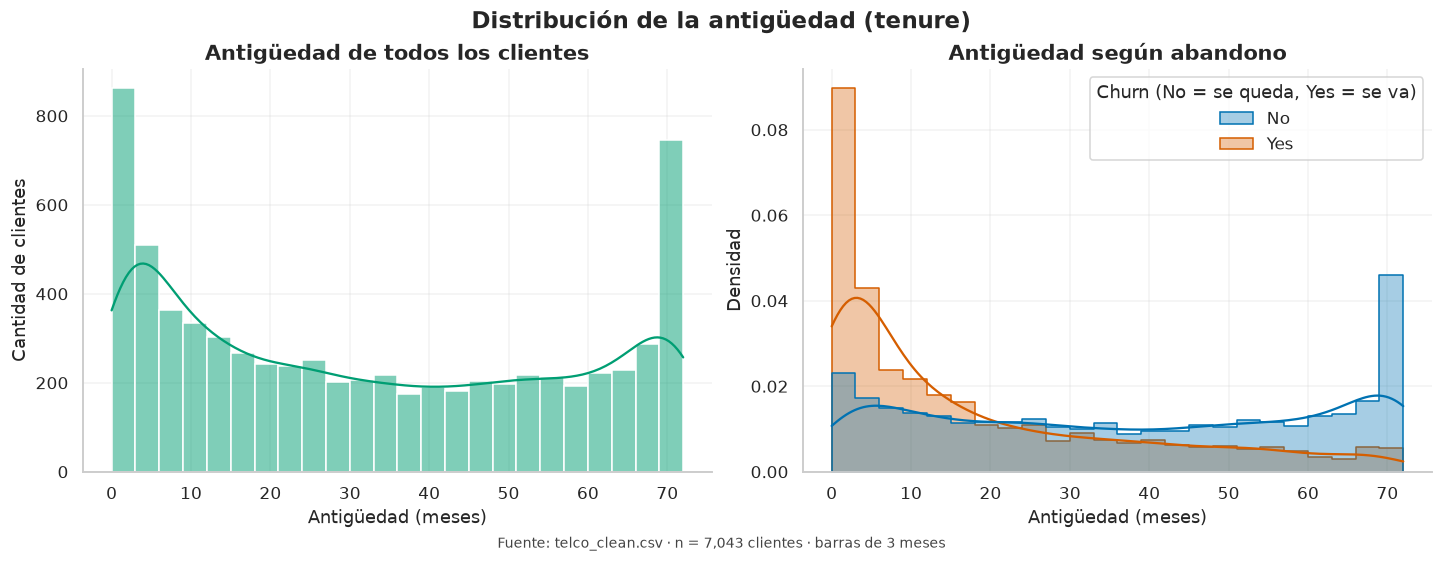

Figura exportada: reports/figures/17_histograma_tenure.png


In [3]:
fig, (ax_total, ax_churn) = plt.subplots(1, 2, figsize=(13, 5), layout='constrained', sharex=True)

sns.histplot(
    data=df, x='tenure', binwidth=3, binrange=(0, 72),
    kde=True, kde_kws={'clip': (0, 72)},
    color=PALETA_CATEGORICA[2], edgecolor='white', ax=ax_total,
)
ax_total.set_title('Antigüedad de todos los clientes')
ax_total.set_xlabel('Antigüedad (meses)')
ax_total.set_ylabel('Cantidad de clientes')

sns.histplot(
    data=df, x='tenure', hue='Churn', hue_order=['No', 'Yes'], palette=COLORES_CHURN,
    binwidth=3, binrange=(0, 72), stat='density', common_norm=False,
    element='step', fill=True, alpha=0.35,
    kde=True, kde_kws={'clip': (0, 72)}, ax=ax_churn,
)
ax_churn.set_title('Antigüedad según abandono')
ax_churn.set_xlabel('Antigüedad (meses)')
ax_churn.set_ylabel('Densidad')
ax_churn.legend_.set_title('Churn (No = se queda, Yes = se va)')

fig.suptitle('Distribución de la antigüedad (tenure)', fontsize=15, fontweight='bold')
fig.supxlabel(f'Fuente: telco_clean.csv · n = {len(df):,} clientes · barras de 3 meses', fontsize=9, color='#444444')

ruta = guardar_figura(fig, '17_histograma_tenure')
plt.show()
plt.close(fig)
print(f'Figura exportada: {ruta.relative_to(RAIZ).as_posix()}')

In [4]:
t = df['tenure']
print(f'Media: {t.mean():.1f} meses · Mediana: {t.median():.1f} meses')
print(f'Clientes con 6 meses o menos: {(t <= 6).mean():.1%}')
print(f'Clientes con el máximo de 72 meses: {(t == 72).sum():,} ({(t == 72).mean():.1%})')
print()
print('Antigüedad mediana según Churn (meses):')
print(df.groupby('Churn')['tenure'].median().to_string())
print()
print(f'Tasa de abandono con 6 meses o menos: {(df.loc[t <= 6, "Churn"] == "Yes").mean():.1%}')
print(f'Tasa de abandono con 61 meses o más: {(df.loc[t >= 61, "Churn"] == "Yes").mean():.1%}')

Media: 32.4 meses · Mediana: 29.0 meses
Clientes con 6 meses o menos: 21.0%
Clientes con el máximo de 72 meses: 362 (5.1%)

Antigüedad mediana según Churn (meses):
Churn
No     38.0
Yes    10.0

Tasa de abandono con 6 meses o menos: 52.9%
Tasa de abandono con 61 meses o más: 6.6%


### Interpretación de la antigüedad

- **La distribución tiene dos picos.** Hay una concentración de clientes muy nuevos (alrededor del 21 % tiene 6 meses o menos) y otra de clientes muy antiguos (362 llegan al máximo de 72 meses). Entre ambos extremos hay menos clientes. La media (32,4 meses) y la mediana (29 meses) quedan en una zona intermedia donde casi no hay un grupo típico, por lo que conviene no resumir la antigüedad con un solo promedio.
- **Quienes se van tienen mucha menos antigüedad.** La mediana de antigüedad de quienes se van es de 10 meses, frente a 38 meses de quienes se quedan. En el panel derecho, la curva naranja se concentra a la izquierda (primeros meses) y la azul se reparte hacia la derecha.
- **El riesgo es mayor al inicio de la relación.** La tasa de abandono es de 52,9 % entre clientes con 6 meses o menos y de 6,6 % entre quienes llevan 61 meses o más.

**Para el negocio:** los primeros meses son el momento crítico. Conviene concentrar los esfuerzos de retención (bienvenida, seguimiento, ofertas) en clientes nuevos. Es una asociación observada en los datos: no prueba por sí sola que la antigüedad cause el abandono, ya que los clientes nuevos pueden diferir en otros aspectos, como el tipo de contrato.

## 4. Cargo mensual (`MonthlyCharges`)

`MonthlyCharges` es lo que paga el cliente por mes. Mismo esquema: a la izquierda, todos los clientes; a la derecha, la comparación entre quienes se quedan y quienes se van.

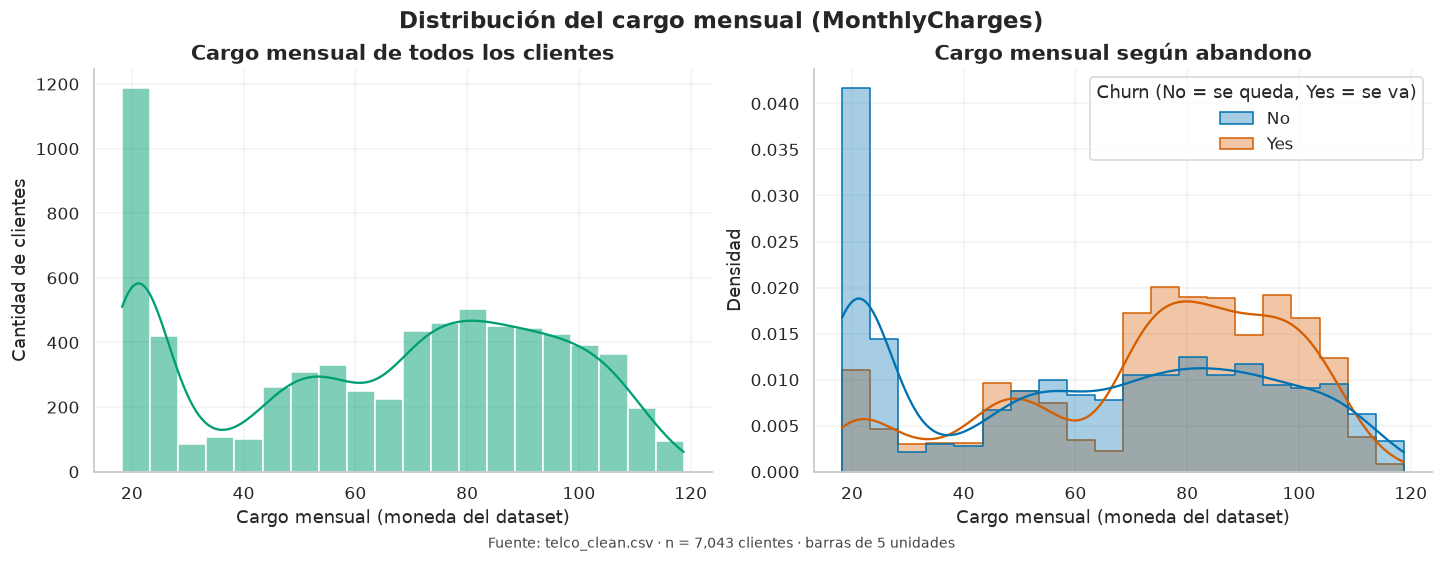

Figura exportada: reports/figures/17_histograma_cargo_mensual.png


In [5]:
minimo, maximo = df['MonthlyCharges'].min(), df['MonthlyCharges'].max()

fig, (ax_total, ax_churn) = plt.subplots(1, 2, figsize=(13, 5), layout='constrained', sharex=True)

sns.histplot(
    data=df, x='MonthlyCharges', binwidth=5,
    kde=True, kde_kws={'clip': (minimo, maximo)},
    color=PALETA_CATEGORICA[2], edgecolor='white', ax=ax_total,
)
ax_total.set_title('Cargo mensual de todos los clientes')
ax_total.set_xlabel('Cargo mensual (moneda del dataset)')
ax_total.set_ylabel('Cantidad de clientes')

sns.histplot(
    data=df, x='MonthlyCharges', hue='Churn', hue_order=['No', 'Yes'], palette=COLORES_CHURN,
    binwidth=5, stat='density', common_norm=False,
    element='step', fill=True, alpha=0.35,
    kde=True, kde_kws={'clip': (minimo, maximo)}, ax=ax_churn,
)
ax_churn.set_title('Cargo mensual según abandono')
ax_churn.set_xlabel('Cargo mensual (moneda del dataset)')
ax_churn.set_ylabel('Densidad')
ax_churn.legend_.set_title('Churn (No = se queda, Yes = se va)')

fig.suptitle('Distribución del cargo mensual (MonthlyCharges)', fontsize=15, fontweight='bold')
fig.supxlabel(f'Fuente: telco_clean.csv · n = {len(df):,} clientes · barras de 5 unidades', fontsize=9, color='#444444')

ruta = guardar_figura(fig, '17_histograma_cargo_mensual')
plt.show()
plt.close(fig)
print(f'Figura exportada: {ruta.relative_to(RAIZ).as_posix()}')

In [6]:
m = df['MonthlyCharges']
print(f'Media: {m.mean():.2f} · Mediana: {m.median():.2f}')
print(f'Clientes que pagan menos de 30: {(m < 30).mean():.1%}')
print(f'Clientes que pagan entre 70 y 100: {((m >= 70) & (m <= 100)).mean():.1%}')
print()
print('Cargo mensual mediano según Churn:')
print(df.groupby('Churn')['MonthlyCharges'].median().round(2).to_string())
print()
print(f'Tasa de abandono con cargo menor a 30: {(df.loc[m < 30, "Churn"] == "Yes").mean():.1%}')
print(f'Tasa de abandono con cargo entre 70 y 100: {(df.loc[(m >= 70) & (m <= 100), "Churn"] == "Yes").mean():.1%}')

Media: 64.76 · Mediana: 70.35
Clientes que pagan menos de 30: 23.5%
Clientes que pagan entre 70 y 100: 38.2%

Cargo mensual mediano según Churn:
Churn
No     64.43
Yes    79.65

Tasa de abandono con cargo menor a 30: 9.8%
Tasa de abandono con cargo entre 70 y 100: 38.0%


### Interpretación del cargo mensual

- **Hay dos grupos de clientes según lo que pagan.** Un grupo grande paga poco (el 23,5 % paga menos de 30, con un pico marcado alrededor de 20) y otro grupo paga bastante (el 38,2 % paga entre 70 y 100). En el medio hay pocos clientes. Por eso la media (64,76) queda por debajo de la mediana (70,35) y tampoco describe bien a ninguno de los dos grupos.
- **Quienes se van pagan más.** La mediana de cargo mensual de quienes se van es de 79,65, frente a 64,43 de quienes se quedan. En el panel derecho, la curva naranja pesa más hacia los cargos altos y la azul tiene un pico en los cargos bajos.
- **Los cargos bajos casi no abandonan.** La tasa de abandono es de 9,8 % entre quienes pagan menos de 30 y de 38,0 % entre quienes pagan entre 70 y 100.

**Para el negocio:** el abandono se concentra en los clientes que pagan más. Conviene revisar si ese cargo alto responde a servicios adicionales de valor percibido y evaluar ofertas o planes ajustados para ese segmento. Es una asociación, no una causa: los cargos altos suelen venir acompañados de ciertos servicios (por ejemplo, fibra óptica) o tipos de contrato que también pueden influir en el abandono, y eso se investiga en las otras tareas de EDA.

## 5. Conclusión de la tarea

Los dos gráficos coinciden en una idea: **el abandono se concentra en clientes nuevos y de cargo mensual alto.** Ambas distribuciones tienen forma de dos grupos, por lo que los promedios resumen mal el comportamiento. Las dos figuras quedaron exportadas en `reports/figures/` (`17_histograma_tenure.png` y `17_histograma_cargo_mensual.png`) para el informe y la defensa.